# Plots/Code planning
Reference
https://www.edmundoptics.com/knowledge-center/application-notes/lasers/gaussian-beam-propagation/?srsltid=AU7gw4Wk_bOM1iuVRBEbyqg-rIR2BDgFoJxu6BU0yIpQYLzWklX0KwEP

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Get constants
a. Calculate waist

$$w_0 = \frac{w_\text{in}}{\sqrt{1 + (z_{R,\text{in}}/f)^2}}, \qquad z_{R,\text{in}} = \frac{\pi w_\text{in}^2}{M^2 \lambda}$$

b. Calculate Zr for post lens

$$z_R = \frac{\pi w_0^2}{M^2 \lambda}$$

In [2]:
lam  = 1030e-9          # wavelength [m]
f    = 100e-3           # lens focal length [m]
w_in = 9.625e-3 / 2     # 1/e^2 beam radius at lens [m]
M2   = 1.0              # beam quality

# a. waist
zR_in = np.pi * w_in**2 / (M2 * lam)
w0 = w_in / np.sqrt(1 + (zR_in / f)**2)

# b. Rayleigh range after lens
zR = np.pi * w0**2 / (M2 * lam)

print(f"zR_in = {zR_in:.2f} m")
print(f"w0    = {w0*1e6:.2f} um")
print(f"zR    = {zR*1e3:.3f} mm")

zR_in = 70.64 m
w0    = 6.81 um
zR    = 0.142 mm


## 2. Beam radius size vs distance from lens (1 2D graph)
- Physics dictates that this will be the same size regardless of what angle it hits at

Equation:

$$w(z) = w_0 \sqrt{1 + \left(\frac{z}{z_R}\right)^2}$$

- Plot this for intuition
- Also an array we'll need to pass in to the rest of the notebook
- Z = distance from focal spot

In [3]:
z = np.linspace(-10e-3, 10e-3, 401)    # distance from focal spot [m]

w = w0 * np.sqrt(1 + (z / zR)**2)       # beam radius [m]

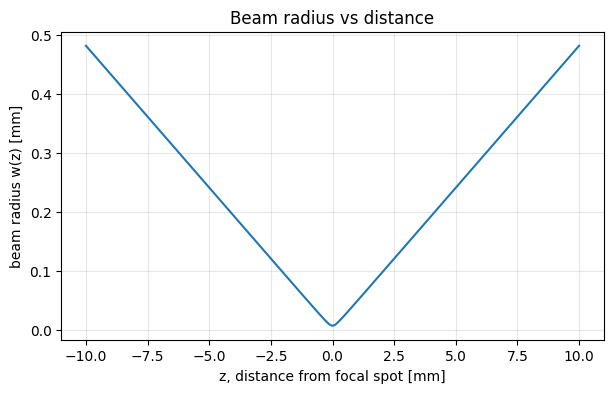

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(z*1e3, w*1e3)
plt.xlabel("z, distance from focal spot [mm]")
plt.ylabel("beam radius w(z) [mm]")
plt.title("Beam radius vs distance")
plt.grid(alpha=0.3)
plt.show()

## 3. Angle accounts (2 graphs: 1 2D, 1 3D)
- Beam will land as an ellipse
- Stretches the effective mirror thickness
- This is what we'll be looking at the most for deciding a radius

Equation: look at the stretched radius only

$$w(z) = w_0 \sqrt{1 + \left(\frac{z}{z_R}\right)^2} \Big/ \cos(\theta)$$

- Theta = angle of incidence on mirror
- Heatmap of radius stretched radius size vs distance and angles

In [5]:
theta = np.radians(np.linspace(0, 70, 141))     # angle of incidence [rad]

TH, Z = np.meshgrid(theta, z, indexing="ij")     # shape (n_theta, n_z)
W = w0 * np.sqrt(1 + (Z / zR)**2)                # beam radius at each z
W_str = W / np.cos(TH)                           # stretched radius [m]

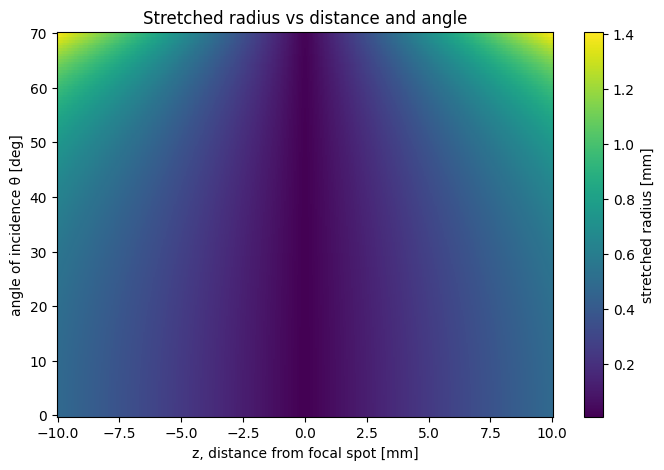

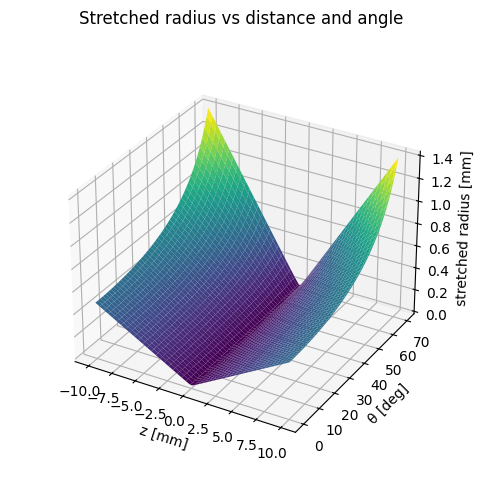

In [6]:
# 2D: heatmap
plt.figure(figsize=(8, 5))
pc = plt.pcolormesh(z*1e3, np.degrees(theta), W_str*1e3, shading="auto", cmap="viridis")
plt.colorbar(pc, label="stretched radius [mm]")
plt.xlabel("z, distance from focal spot [mm]")
plt.ylabel("angle of incidence θ [deg]")
plt.title("Stretched radius vs distance and angle")
plt.show()

# 3D: surface
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.set_box_aspect(None, zoom=0.85)
ax.plot_surface(Z*1e3, np.degrees(TH), W_str*1e3, cmap="viridis")
ax.set_xlabel("z [mm]")
ax.set_ylabel("θ [deg]")
ax.set_zlabel("stretched radius [mm]")
ax.set_title("Stretched radius vs distance and angle")
plt.show()

## 4. How much is getting clipped
- For each radius calculated in the angle accounts 3D plot, want to now look at how much power is leaking out if we do the effective radius calculated in 2
    - Assuming spherical hole
- Intensity vs distance from centre:

$$I(r) = I_0 \exp\left(-2\frac{r^2}{w^2}\right) = \frac{2P}{\pi w^2} \exp\left(-2\frac{r^2}{w^2}\right),$$

- Power inside a radius = integral
- Idea: power inside a disk is

$$P_\text{in}(a) = \int_0^a \frac{2P}{\pi w^2} e^{-2r^2/w^2}\, 2\pi r\, dr = P\left(1 - e^{-2a^2/w^2}\right)$$

- To account for the angle, change the disk to an ellipse
    - Change the upper bound to be dependent on direction and plug in he ellipse equation

$$P_\text{in} = \int_0^{2\pi} \left[ \int_0^{\rho(\varphi)} \frac{2P}{\pi w^2} e^{-2r^2/w^2}\, r\, dr \right] d\varphi$$

- Leakage = everything outside that

$$L = 1 - \frac{P_\text{in}}{P} = \frac{1}{2\pi} \int_0^{2\pi} e^{-2\rho(\varphi)^2/w^2}\, d\varphi$$

In [7]:
k = 1.0                                   # hole radius = k * stretched radius (k=1 -> hole = W_str)
R = k * W_str                             # round hole radius on mirror [m]

# ellipse seen by the beam: A along tilt, B across tilt
A = R * np.cos(TH)
B = R
phi = np.linspace(0, 2*np.pi, 720, endpoint=False)

rho2 = 1 / (np.cos(phi)**2 / A[..., None]**2 + np.sin(phi)**2 / B[..., None]**2)
L = np.mean(np.exp(-2 * rho2 / W[..., None]**2), axis=-1)   # (1/2π)∫ ... dφ

print(f"check θ=0: L = {L[0,0]:.4f}, exp(-2k^2) = {np.exp(-2*k**2):.4f}")

check θ=0: L = 0.1353, exp(-2k^2) = 0.1353


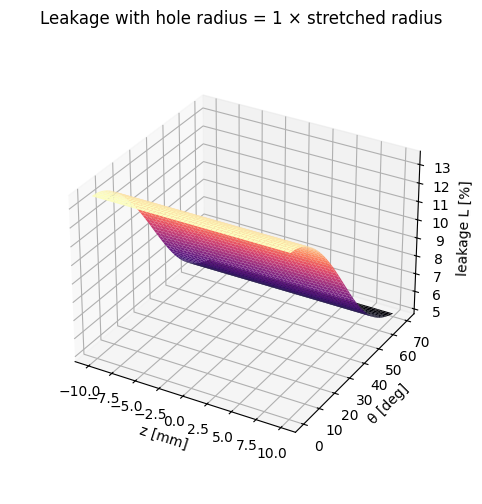

In [8]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.set_box_aspect(None, zoom=0.85)
ax.plot_surface(Z*1e3, np.degrees(TH), L*100, cmap="magma")
ax.set_xlabel("z [mm]")
ax.set_ylabel("θ [deg]")
ax.set_zlabel("leakage L [%]")
ax.set_title(f"Leakage with hole radius = {k:g} × stretched radius")
plt.show()